# Follow-up analyses: how each figure was made

This notebook rebuilds every figure from the follow-up analyses after the ISMRM 2027 abstract from the regional values in `data/`, and explains each step: what goes in, the exact calculation, how to read the plot, and the caveats someone may ask about.

Each section ends with a **check** that the numbers recomputed here equal the ones in `results/followup/followup.json`, which is what was reported to the co-authors. If a check fails, the notebook stops.

**Data version.** QSM-CI harmonization run with QSMxT v10.0.0 (October 2026): 6 subjects, 12 sessions, 72 acquisitions, 638 pipelines. The five sessions acquired in October and the re-run on QSMxT v11 are not included, so these numbers will change.

| Fig. | Question | One-line answer |
|---|---|---|
| 1 | Should scan-rescan use the SD of *a* instead of median \|a − 1\|? | Same conclusion either way: bridge 3.3% vs local 2.2% (SD), 2.2% vs 1.4% (median). For a normal spread centred on 1 the two differ by a fixed factor of 0.674. |
| 2 | How much does the inter-scanner deviation vary between scanner pairs? | The IQR across the 7 scanner pairs (≈ 6%) is about as large as the median deviation itself, but each pair is a different subject. |
| 3 | Should the limits of agreement be taken after removing the scaling? | Removing each pair's fitted scale narrows the LoA by only 5–8%, so most of the disagreement is regions scattering independently. |
| 4 | What is the "Protocol" bar in Fig. 4 of the abstract? | The SD of two numbers, the bridge and local run-averaged means. Removing a scale fitted on the same scans takes it to roughly rescan level, but that is a best case. |
| 5 | Can pipelines be converted with one factor each? | Yes, partly. One factor per pipeline, learned on site-1 bridge scans, halves the spread between pipelines (pallidum 29–34 → 16–17 ppb). What remains is still larger than the scanner or protocol spread. |
| 6 | Does a local-to-bridge calibration help a new subject? | No (4.0% → 4.2%). The local-to-bridge slope changes 3–5% from one subject to the next, and the protocols are already close (median slope 0.99). |
| 7 | Why is the bridge scan-rescan noisier? | Mostly because of bridge run 1. In 9 of 12 sessions, run 2 vs run 3 is the best-agreeing of the three bridge pairs (p ≈ 0.004). |
| 8 | Does dropping run 1 change the results? | Test-retest: bridge 1.6% vs local 1.5%. Inter-scanner: essentially unchanged. |

## Setup

In [1]:
import json
import sys

sys.path.insert(0, 'analysis'); sys.path.insert(0, 'figures/src')
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import binom

import emtp
import followup  # helper functions only; nothing is written by importing it

pd.set_option('display.precision', 2)
FIGDIR = Path('figures/followup'); FIGDIR.mkdir(parents=True, exist_ok=True)
FU = json.load(open('results/followup/followup.json'))   # the reported follow-up values
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
BRIDGE, LOCAL = '#2a78d6', '#eb6834'


def check(name, got, expected, tol=0.051):
    """Stop if a recomputed value differs from results/followup/followup.json."""
    assert abs(got - expected) <= tol, f'{name}: recomputed {got:.3f}, followup.json {expected:.3f}'
    print(f'check ok  {name}: {got:.2f} (followup.json {expected:.2f})')


reg = emtp.regions()          # pipeline x acquisition x region: mean chi (ppm, minus the whole-brain mean)
acq = emtp.acquisitions()     # acquisition -> subject, scanner, protocol, run
print(f'{reg.pipeline.nunique()} pipelines, {acq.shape[0]} acquisitions, {reg.label.nunique()} regions')
acq.groupby(['subject', 'scanner']).size().unstack(fill_value=0)

638 pipelines, 72 acquisitions, 25 regions


scanner,site1-achieva,site1-elition,site4-skyra,site5-mr750,site5-prisma,site6-ingenia
subject,,,,,,
s002001,6,0,0,0,0,0
s003001,6,0,0,0,0,0
s004001,6,0,6,0,0,0
s005001,0,6,0,6,6,0
s005002,6,0,0,6,6,0
s006001,6,0,0,0,0,6


**Design.** Each cell above is one session: 3 bridge runs + 3 local runs, always in the order **B1 L1 B2 L2 B3 L3**. Every subject was scanned on the reference scanner of site 1, except s005001, who was scanned on the site-1 Elition instead. Only four subjects have more than one scanner (s004001, s005001, s005002, s006001), so all the inter-scanner results rest on those four people.

**Regional values** (`data/regional_chi.csv.gz`, extracted by QSM-CI; see `extraction/README.md`). Every reconstruction is rigidly registered to the subject's reference scan and segmented once with SynthSeg on the reference magnitude. For each of 25 labels (left and right hemispheres separate: deep grey matter, thalamus, hippocampus, amygdala, cortex, WM, cerebellum, brainstem, ventral DC) we take the mean χ **minus the whole-brain mean of that reconstruction**. A label is dropped from a scan if under 90% of it is inside the reconstruction.

## The building block: one orthogonal fit per scan pair

Every agreement number here comes from one kind of calculation. Take one pipeline and two scans of the same subject, x (the reference) and y. Each region gives a point $(x_i, y_i)$: its mean χ in scan x and in scan y. We use only regions present in both scans, which is 21–25 of them.

We fit $y = a\,x + b$ by **orthogonal (total least squares) regression**. This minimises the squared *perpendicular* distances of the points from the line, so x and y are treated the same way (both scans are noisy). The solution is the first principal component of the centred point cloud. With $s_{xx}, s_{yy}, s_{xy}$ the sample (co)variances:

$$a = \frac{s_{yy} - s_{xx} + \sqrt{(s_{yy} - s_{xx})^2 + 4 s_{xy}^2}}{2 s_{xy}}, \qquad b = \bar y - a\,\bar x$$

- **Slope deviation** $|a - 1|$, in %: how far the second scan is scaled relative to the first. Perfect agreement gives $a = 1$. Swapping x and y gives exactly $1/a$, so the direction only matters at second order ($|1/a - 1| \approx |a - 1|$ for small deviations).
- **Bland–Altman limits of agreement** (half-width, ppb): $\mathrm{LoA} = 1.96\,\mathrm{SD}_i(y_i - x_i)$, with sample SD (ddof = 1). The bias $\overline{y - x}$ is stored separately.
- **Scale-corrected LoA**: $1.96\,\mathrm{SD}_i\big(y_i - (a x_i + b)\big)$, the scatter left after removing this pair's own fitted line.

QSM-CI's exclusion rules: no fit with fewer than 8 shared regions, with a flat map, or when $|a - 1| > 200\%$ (a failed reconstruction, not a reproducibility value).

Here is one example. The session is s005001 on the site-1 Elition, bridge protocol, the clearest run-1 case (Fig. 7). The pipeline is ROMEO + V-SHARP + MEDI.

run2 vs run1: 23 regions, a = 0.924 (|a-1| = 7.6%), b = 0.2 ppb, LoA ±11.7 ppb, scale-corrected LoA ±9.3 ppb
run3 vs run2: 24 regions, a = 0.970 (|a-1| = 3.0%), b = -3.6 ppb, LoA ±16.4 ppb, scale-corrected LoA ±16.0 ppb


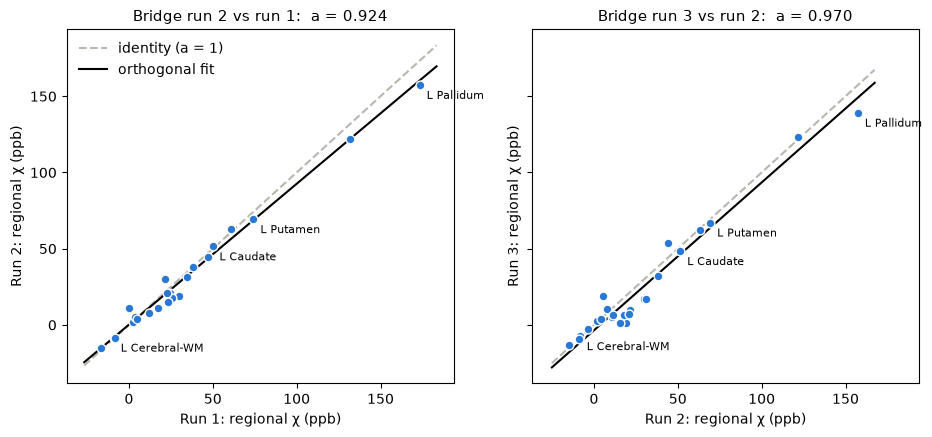

In [2]:
PIPE, SESSION = 'romeo-qsmrs+vsharp-qsmrs+medi-qsmrs', 's005001-site1-elition-bridge'
v = {r: reg[(reg.pipeline == PIPE) & (reg.acquisition == f'{SESSION}-{r}')].set_index('region').mean_ppm * 1000
     for r in ('run1', 'run2', 'run3')}


def tls_closed_form(x, y):
    sxx, syy, sxy = np.var(x, ddof=1), np.var(y, ddof=1), np.cov(x, y)[0, 1]
    return (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)


fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, (rx, ry) in zip(axs, [('run1', 'run2'), ('run2', 'run3')]):
    common = v[rx].index.intersection(v[ry].index)
    x, y = v[rx][common].values, v[ry][common].values
    f = emtp.fit(x, y)                      # the function used for every pair (works in any unit; here ppb)
    assert np.isclose(f['slope'], tls_closed_form(x, y))
    assert np.isclose(emtp.fit(y, x)['slope'], 1 / f['slope'])      # symmetric: swapping the scans gives 1/a
    print(f"{ry} vs {rx}: {len(common)} regions, a = {f['slope']:.3f} (|a-1| = {100 * abs(f['slope'] - 1):.1f}%), "
          f"b = {f['intercept_ppm']:.1f} ppb, LoA ±{f['ba_loa_ppm']:.1f} ppb, scale-corrected LoA ±{f['ba_loa_corrected_ppm']:.1f} ppb")
    lo, hi = min(x.min(), y.min()) - 10, max(x.max(), y.max()) + 10
    ax.plot([lo, hi], [lo, hi], color='#b9b6ae', ls='--', label='identity (a = 1)')
    ax.plot([lo, hi], [f['slope'] * lo + f['intercept_ppm'], f['slope'] * hi + f['intercept_ppm']], color='k', label='orthogonal fit')
    ax.scatter(x, y, s=40, color='#2a78d6', edgecolors='white', zorder=3)
    for name in ('Left-Pallidum', 'Left-Putamen', 'Left-Caudate', 'Left-Cerebral-WM'):
        if name in common:
            ax.annotate(name.replace('Left-', 'L '), (v[rx][name], v[ry][name]), xytext=(5, -10), textcoords='offset points', fontsize=8)
    ax.set_title(f"Bridge {ry.replace('run', 'run ')} vs {rx.replace('run', 'run ')}:  a = {f['slope']:.3f}", fontsize=11)
    ax.set_xlabel(f"{rx.replace('run', 'Run ')}: regional χ (ppb)"); ax.set_ylabel(f"{ry.replace('run', 'Run ')}: regional χ (ppb)")
axs[0].legend(frameon=False)
fig.savefig(FIGDIR / 'example_fit.png', dpi=200, bbox_inches='tight')

Note what drives the slope: a few high-χ regions (pallidum, putamen) sit far from the rest, so they have most of the leverage. The cortex, WM and cerebellum cluster near zero. A slope deviation is therefore mostly saying "deep grey matter is scaled up or down relative to the rest of the brain".

### The pairs

`emtp.comparison_plan` defines which scans get compared (the same as QSM-CI). Pairs never cross subjects.

| Comparison | Pairs | Per pipeline and protocol |
|---|---|---|
| **test_retest** | same session and protocol, every two runs (1–2, 1–3, 2–3); x = earlier run | 12 sessions × 3 = **36** |
| **inter_scanner** | same subject and protocol, every run on one scanner against every run on the other (different days, so run numbers don't correspond); x = the site-1 scanner | 8 session pairs × 9 = **72** (7 distinct scanner pairs) |
| **inter_protocol** | same session, bridge run k vs local run k (acquired one after the other); x = bridge | 12 × 3 = **36** |

The diagram below draws the three kinds of pair. The counts in its titles come from `emtp.comparison_plan` itself, and panel D from the acquisition table.

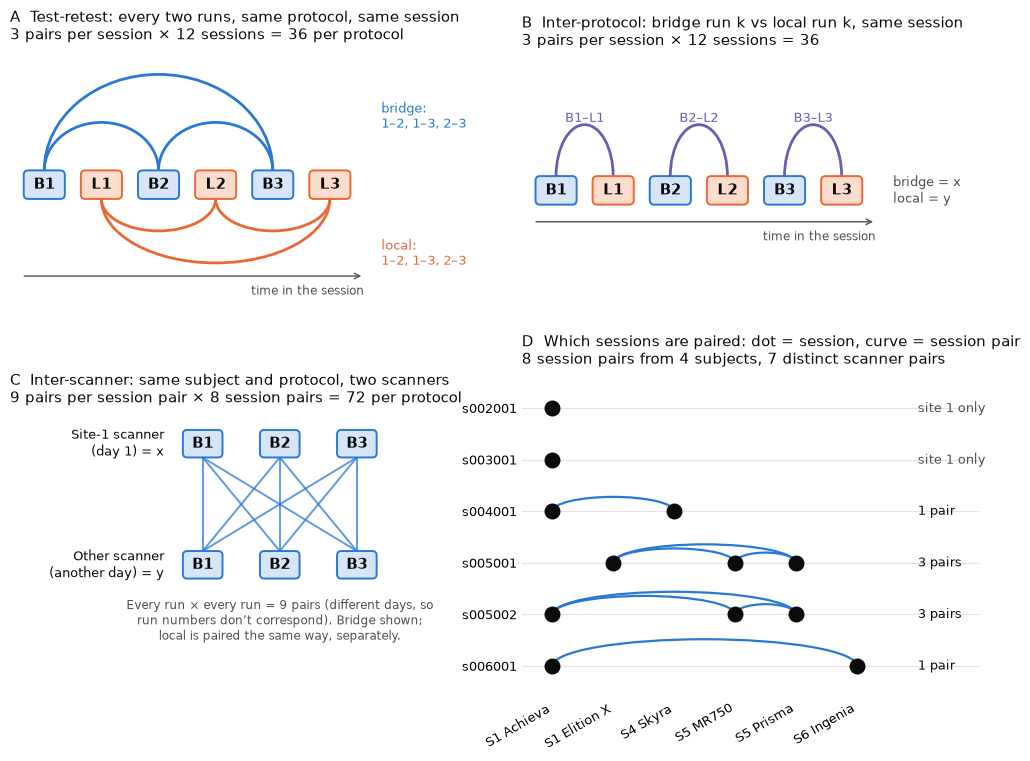

In [3]:
from matplotlib.patches import Arc, FancyBboxPatch

plan = pd.DataFrame(emtp.comparison_plan(acq), columns=['comparison', 'x', 'y'])
amap = acq.set_index('acquisition')
plan['protocol'] = plan.x.map(amap.protocol)
n_pairs = plan[plan.protocol == 'bridge'].comparison.value_counts()      # per protocol (bridge shown; local is the same)
n_pairs['inter_protocol'] = (plan.comparison == 'inter_protocol').sum()
n_sessions = acq.groupby(['subject', 'scanner']).ngroups
LIGHT = {'B': '#d6e6f8', 'L': '#fbdccd'}
EDGE = {'B': BRIDGE, 'L': LOCAL}
PAIR_COL = '#6b5bb3'


def scan_box(ax, x, y, lab, w=0.72, h=0.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0,rounding_size=0.08',
                                facecolor=LIGHT[lab[0]], edgecolor=EDGE[lab[0]], lw=1.4, zorder=3))
    ax.text(x, y, lab, ha='center', va='center', fontsize=11, fontweight='bold', color=INK, zorder=4)


def arc(ax, x0, x1, y, col, up=True, h_per=0.42, lw=2):
    w = abs(x1 - x0)
    ax.add_patch(Arc(((x0 + x1) / 2, y), w, w * h_per * 2, theta1=0 if up else 180, theta2=180 if up else 360,
                     color=col, lw=lw, zorder=2))


def session_strip(ax, y=0, arrow_y=-0.55, labels=('B1', 'L1', 'B2', 'L2', 'B3', 'L3')):
    for i, lab in enumerate(labels):
        scan_box(ax, i, y, lab)
    ax.annotate('', (5.6, arrow_y), (-0.4, arrow_y), arrowprops=dict(arrowstyle='->', color=INK2, lw=1))
    ax.text(5.6, arrow_y - 0.15, 'time in the session', ha='right', va='top', fontsize=8.5, color=INK2)


def clean(ax, xlim, ylim):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect('equal'); ax.axis('off')


fig = plt.figure(figsize=(12.5, 8.6), facecolor='white')
gs = fig.add_gridspec(2, 2, hspace=0.18, wspace=0.12, height_ratios=[1, 1.15])

# A: test-retest, every two runs of the same protocol in one session
ax = fig.add_subplot(gs[0, 0])
session_strip(ax, arrow_y=-1.6)
for i, j in ((0, 2), (0, 4), (2, 4)):
    arc(ax, i, j, 0.25, BRIDGE, up=True)
for i, j in ((1, 3), (1, 5), (3, 5)):
    arc(ax, i, j, -0.25, LOCAL, up=False, h_per=0.28)
ax.text(5.9, 1.2, 'bridge:\n1–2, 1–3, 2–3', color=BRIDGE, fontsize=9, va='center')
ax.text(5.9, -1.2, 'local:\n1–2, 1–3, 2–3', color=LOCAL, fontsize=9, va='center')
clean(ax, (-0.6, 7.4), (-2.1, 2.4))
ax.set_title(f'A  Test-retest: every two runs, same protocol, same session\n'
             f'3 pairs per session × {n_sessions} sessions = {n_pairs.test_retest} per protocol', loc='left', fontsize=10.5, color=INK)

# B: inter-protocol, bridge run k against local run k (acquired back to back)
ax = fig.add_subplot(gs[0, 1])
session_strip(ax)
for k in range(3):
    arc(ax, 2 * k, 2 * k + 1, 0.25, PAIR_COL, up=True, h_per=0.9)
    ax.text(2 * k + 0.5, 0.25 + 0.95, f'B{k + 1}–L{k + 1}', ha='center', fontsize=9, color=PAIR_COL)
ax.text(5.9, 0, 'bridge = x\nlocal = y', fontsize=9, color=INK2, va='center')
clean(ax, (-0.6, 7.4), (-1.9, 2.4))
ax.set_title(f'B  Inter-protocol: bridge run k vs local run k, same session\n'
             f'3 pairs per session × {n_sessions} sessions = {n_pairs.inter_protocol}', loc='left', fontsize=10.5, color=INK)

# C: inter-scanner, every run on one scanner against every run on the other
ax = fig.add_subplot(gs[1, 0])
yA, yB = 2.2, 0
for k in range(3):
    scan_box(ax, 1.4 * k + 1.6, yA, f'B{k + 1}'); scan_box(ax, 1.4 * k + 1.6, yB, f'B{k + 1}')
for i in range(3):
    for j in range(3):
        ax.plot([1.4 * i + 1.6, 1.4 * j + 1.6], [yA - 0.25, yB + 0.25], color=BRIDGE, lw=1.4, alpha=0.75, zorder=1)
ax.text(0.9, yA, 'Site-1 scanner\n(day 1) = x', ha='right', va='center', fontsize=9.5, color=INK)
ax.text(0.9, yB, 'Other scanner\n(another day) = y', ha='right', va='center', fontsize=9.5, color=INK)
ax.text(3.0, -0.6, 'Every run × every run = 9 pairs (different days, so\nrun numbers don’t correspond). Bridge shown;\nlocal is paired the same way, separately.', ha='center', va='top', fontsize=8.5, color=INK2)
clean(ax, (-1.9, 6.4), (-1.7, 2.8))
n_sess_pairs = n_pairs.inter_scanner // 9
ax.set_title(f'C  Inter-scanner: same subject and protocol, two scanners\n'
             f'9 pairs per session pair × {n_sess_pairs} session pairs = {n_pairs.inter_scanner} per protocol', loc='left', fontsize=10.5, color=INK)

# D: which sessions are paired (one dot per session; lines = session pairs)
ax = fig.add_subplot(gs[1, 1])
SCN = ['site1-achieva', 'site1-elition', 'site4-skyra', 'site5-mr750', 'site5-prisma', 'site6-ingenia']
SUB = sorted(acq.subject.unique())
sess = acq[['subject', 'scanner']].drop_duplicates()
for (s, g) in sess.groupby('subject'):
    ys = SUB.index(s); xs = sorted(SCN.index(c) for c in g.scanner)
    for i, a_ in enumerate(xs):
        for b_ in xs[i + 1:]:
            w = b_ - a_   # curve height grows with span but stays inside the row
            ax.add_patch(Arc(((a_ + b_) / 2, ys), w, 2 * (0.12 + 0.08 * w), theta1=180, theta2=360, color=BRIDGE, lw=1.6, zorder=2))
    n = len(xs) * (len(xs) - 1) // 2
    ax.text(6.0, ys, f'{n} pair' + ('s' if n != 1 else '') if n else 'site 1 only', fontsize=9, va='center',
            color=INK if n else INK2)
for r in sess.itertuples():
    ax.scatter(SCN.index(r.scanner), SUB.index(r.subject), s=110, color=INK, zorder=3)
for i in range(len(SUB)):
    ax.axhline(i, color=GRID, lw=0.8, zorder=0)
ax.set_xticks(range(len(SCN)))
MODEL = {'achieva': 'Achieva', 'elition': 'Elition X', 'ingenia': 'Ingenia', 'mr750': 'MR750', 'prisma': 'Prisma', 'skyra': 'Skyra'}
ax.set_xticklabels([f"S{c.split('-')[0][4:]} {MODEL[c.split('-')[1]]}" for c in SCN], rotation=30, ha='right', fontsize=9)
ax.set_yticks(range(len(SUB))); ax.set_yticklabels(SUB, fontsize=9)
ax.set_xlim(-0.5, 7); ax.set_ylim(len(SUB) - 0.4, -0.7)
for s in ('top', 'right', 'left', 'bottom'):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
n_scanner_pairs = plan[plan.comparison == 'inter_scanner'].assign(
    p=lambda d: d.x.map(amap.scanner) + '|' + d.y.map(amap.scanner)).p.nunique()
ax.set_title(f'D  Which sessions are paired: dot = session, curve = session pair\n'
             f'{n_sess_pairs} session pairs from 4 subjects, {n_scanner_pairs} distinct scanner pairs', loc='left', fontsize=10.5, color=INK)
fig.savefig(FIGDIR / 'pairs_design.png', dpi=200, bbox_inches='tight', facecolor='white')

Panel D shows why the inter-scanner results rest on four people: s002001 and s003001 were scanned only at site 1. It also shows that S5 MR750 – S5 Prisma is the only scanner pair with two subjects, and that the two site-1 scanners never share a subject.

All 638 pipelines are fitted on every pair (this takes about a minute).

In [4]:
fits = emtp.pair_fits(reg)
ok = fits[fits.excluded == ''].copy()
ok['scanner_pair'] = ok.scanner_x + '|' + ok.scanner_y
ok['with_run1'] = (ok.run_x == 'run1') | (ok.run_y == 'run1')
print('excluded pairs:', fits.excluded.replace('', 'kept').value_counts().to_dict())
ok.groupby(['comparison', 'protocol']).agg(fits=('slope', 'size'), pipelines=('pipeline', 'nunique'),
                                           pairs_per_pipeline=('pipeline', lambda p: p.value_counts().median()))

excluded pairs: {'kept': 160293, 'slope_cap': 462}


fits  pipelines  pairs_per_pipeline
comparison     protocol                                             
inter_protocol local_vs_bridge  22835        638                36.0
inter_scanner  bridge           45886        638                72.0
               local            45653        638                72.0
test_retest    bridge           22959        638                36.0
               local            22960        638                36.0

### How every box plot is summarised

Each pipeline gives **one value**, usually the median of $|a-1|$ over its pairs of the kind in question. The box plots then show how that value is distributed across the 638 pipelines:

- **box** = 25th–75th percentile across pipelines, **thick line** = median (the number printed next to it);
- **whiskers = 5th and 95th percentiles** (not Tukey's 1.5 × IQR);
- **+n** above a capped axis = number of pipelines beyond the cap.

So "bridge 2.2%" means "the median pipeline's median scan-rescan |a − 1| is 2.2%". The same 72 scans are behind all 638 pipelines, so the pipelines are not independent samples. The real sample size is subjects and sessions (see the caveats at the end).

In [5]:
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False})


def box(ax, p, d, col, light=False, cap=None, fmt='{:.1f}', w=0.3, alpha=None):
    """Box = IQR, line = median, whiskers = 5th/95th percentiles; +n = values above `cap`."""
    d = np.asarray(d, dtype=float); d = d[~np.isnan(d)]
    q5, q25, q50, q75, q95 = np.percentile(d, [5, 25, 50, 75, 95])
    ax.add_patch(plt.Rectangle((p - w / 2, q25), w, q75 - q25, facecolor=col, edgecolor=col, lw=1.2,
                               alpha=alpha if alpha is not None else (0.10 if light else 0.22), ls='--' if light else '-'))
    ax.plot([p - w / 2, p + w / 2], [q50, q50], color=col, lw=2.4, solid_capstyle='butt', ls=(0, (2, 1)) if light else '-')
    top = q95 if cap is None else min(q95, cap)
    ax.plot([p, p], [q5, q25], color=col, lw=1.2); ax.plot([p, p], [q75, top], color=col, lw=1.2)
    ax.annotate(fmt.format(q50), (p + w / 2 + 0.01, q50), fontsize=8, color=INK, va='center', bbox=dict(fc='white', ec='none', pad=0.5))
    if cap is not None and (d > cap).sum():
        ax.annotate(f'+{(d > cap).sum()}', (p, cap), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5, color=INK2)


def style(ax, ylabel):
    ax.set_ylabel(ylabel); ax.yaxis.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)


def legend(ax, loc='upper left'):
    ax.legend(handles=[Patch(facecolor=BRIDGE, alpha=0.5, label='Bridge protocol'), Patch(facecolor=LOCAL, alpha=0.5, label='Local protocols')],
              frameon=False, fontsize=9, loc=loc, ncol=2)


# the slide-style figures (5, 7, 8) use a lighter background
DECK = {'font.size': 15, 'axes.labelcolor': '#55606E', 'xtick.color': '#55606E', 'ytick.color': '#1C2430', 'axes.edgecolor': '#55606E',
        'figure.facecolor': '#FAF9F6', 'axes.facecolor': '#FAF9F6', 'savefig.facecolor': '#FAF9F6'}

## Figure 1 · Scan-rescan: median |a − 1| or SD of a?

**Question ([#2](https://github.com/astewartau/emtp-travelling-heads/issues/2)).** Within one scanner and protocol there should be no systematic scaling, so the spread of $a$ (its SD) is the natural measure. Median $|a-1|$ (the median absolute error) is meant for cases with a systematic error.

**Calculation.** Use each pipeline's 36 test-retest fits per protocol (12 sessions × 3 run pairs):
- left boxes: $\mathrm{median}_{\text{pairs}}\,|a-1|$ (as in the abstract);
- right boxes: $\mathrm{SD}_{\text{pairs}}(a)$ (ddof = 1), the suggested measure;
- also $\mathrm{mean}(a) - 1$, to check there is no systematic error.

**Why the two agree.** If $a - 1 \sim \mathcal N(0, \sigma^2)$, then $\mathrm{median}\,|a-1| = 0.674\,\sigma$. Here $0.674 \times 3.29 = 2.2$ and $0.674 \times 2.19 = 1.5$. So the two measures carry the same information and rank the protocols the same way. We kept median |a − 1| as the primary measure (decision D1 in `docs/decisions.md`) so test-retest and inter-scanner use the same scale and match QSM-CI.

,median |a-1| (%),SD of a (%),mean a - 1 (%),ratio median/SD
protocol,,,,
bridge,2.21,3.29,-0.53,0.67
local,1.42,2.19,0.24,0.65


check ok  bridge SD of a: 3.29 (followup.json 3.29)
check ok  bridge mean a - 1: -0.53 (followup.json -0.53)
check ok  local SD of a: 2.19 (followup.json 2.19)
check ok  local mean a - 1: 0.24 (followup.json 0.24)


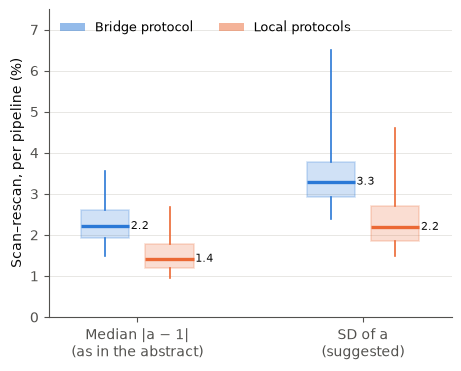

In [6]:
tr = ok[ok.comparison == 'test_retest']
g = tr.groupby(['pipeline', 'protocol'])
med = 100 * g.abs_slope_dev.median().unstack()
sd = 100 * g.slope.std().unstack()
mean_dev = 100 * (g.slope.mean().unstack() - 1)
display(pd.DataFrame({'median |a-1| (%)': med.median(), 'SD of a (%)': sd.median(), 'mean a - 1 (%)': mean_dev.median(),
                      'ratio median/SD': med.median() / sd.median()}).round(2))
s2 = FU['issue_2_slope_spread']
for p in ('bridge', 'local'):
    check(f'{p} SD of a', sd[p].median(), s2[p]['test_retest_sd_slope_pct']['median'])
    check(f'{p} mean a - 1', mean_dev[p].median(), s2[p]['test_retest_mean_slope_minus_1_pct']['median'])

fig, ax = plt.subplots(figsize=(5.2, 4), facecolor='white')
for d, p0 in ((med, 1), (sd, 2.4)):
    box(ax, p0 - 0.2, d.bridge, BRIDGE); box(ax, p0 + 0.2, d.local, LOCAL)
ax.set_xticks([1, 2.4]); ax.set_xticklabels(['Median |a − 1|\n(as in the abstract)', 'SD of a\n(suggested)'])
ax.set_xlim(0.45, 2.95); ax.set_ylim(0, 7.5)
style(ax, 'Scan–rescan, per pipeline (%)'); legend(ax)
fig.savefig(FIGDIR / 'fig1_sd_of_a.png', dpi=200, bbox_inches='tight', facecolor='white')

**How to say it.** "The mean of a is 1 to within half a percent, so there is no systematic error, as you expected. The SD of a gives bridge 3.3% vs local 2.2%, the same conclusion as the median |a − 1|. For a normal spread the two differ by a fixed factor of 0.67."

**Possible questions.**
- *Are the 36 pairs independent?* No. The three pairs in a session share scans: run 1 is in both 1–2 and 1–3. One odd scan therefore inflates two of the three pairs, which is exactly what happens with bridge run 1 (Fig. 7).
- *Why is the bridge SD higher?* Mostly bridge run 1 (Figs. 7–8).

## Figure 2 · Inter-scanner deviation for each scanner pair

**Question ([#2](https://github.com/astewartau/emtp-travelling-heads/issues/2)).** Report the IQR too, to show how much the deviation varies between scanners.

**Calculation.**
1. For each pipeline, scanner pair and protocol: the median $|a-1|$ over that pair's run combinations. That is 9 combinations (3 runs × 3 runs), or 18 for S5 MR750 – S5 Prisma, which has two subjects.
2. Each box shows that value across the 638 pipelines. Pairs are ordered by the mean of their bridge and local medians.
3. **IQR across scanner pairs** (the reported value): for each pipeline, the 75th minus the 25th percentile of its 7 per-pair values, then the median over pipelines.

The headline inter-scanner value (bridge 6.4%, local 7.0%) is computed directly over all 72 pairs per pipeline, not from these per-pair values.

In [7]:
isc = ok[ok.comparison == 'inter_scanner']
per_pipe = 100 * isc.groupby(['pipeline', 'protocol']).abs_slope_dev.median().unstack()
by_pair = 100 * isc.groupby(['pipeline', 'protocol', 'scanner_pair']).abs_slope_dev.median()
q = by_pair.groupby(['pipeline', 'protocol'])
iqr = (q.quantile(.75) - q.quantile(.25)).unstack()
display(pd.DataFrame({'median': per_pipe.median(), 'p75': per_pipe.quantile(.75), 'p95': per_pipe.quantile(.95),
                      'IQR across scanner pairs': iqr.median()}).round(2))
for p in ('bridge', 'local'):
    check(f'{p} inter-scanner median', per_pipe[p].median(), s2[p]['inter_scanner_median_abs_slope_dev_pct']['median'])
    check(f'{p} IQR across scanner pairs', iqr[p].median(), s2[p]['inter_scanner_iqr_across_scanner_pairs_pct']['median'])

# which subjects make up each scanner pair, and the median over pipelines
pairs = (by_pair.groupby(['scanner_pair', 'protocol']).median().unstack()
         .join(isc.groupby('scanner_pair').subject_x.unique().map(', '.join).rename('subjects')))
pairs['same site'] = [a.split('-')[0] == b.split('-')[0] for a, b in pairs.index.str.split('|')]
pairs.sort_values('bridge')

,median,p75,p95,IQR across scanner pairs
protocol,,,,
bridge,6.36,8.56,21.76,6.09
local,6.98,11.11,27.96,5.47


check ok  bridge inter-scanner median: 6.36 (followup.json 6.36)
check ok  bridge IQR across scanner pairs: 6.09 (followup.json 6.09)
check ok  local inter-scanner median: 6.98 (followup.json 6.98)
check ok  local IQR across scanner pairs: 5.47 (followup.json 5.47)


,bridge,local,subjects,same site
scanner_pair,,,,
site1-achieva|site6-ingenia,4.12,3.85,s006001,False
site1-elition|site5-prisma,4.75,8.56,s005001,False
site5-mr750|site5-prisma,6.76,6.80,"s005001, s005002",True
site1-elition|site5-mr750,7.04,5.29,s005001,False
site1-achieva|site5-prisma,8.65,6.21,s005002,False
site1-achieva|site4-skyra,9.19,8.48,s004001,False
site1-achieva|site5-mr750,9.60,6.59,s005002,False


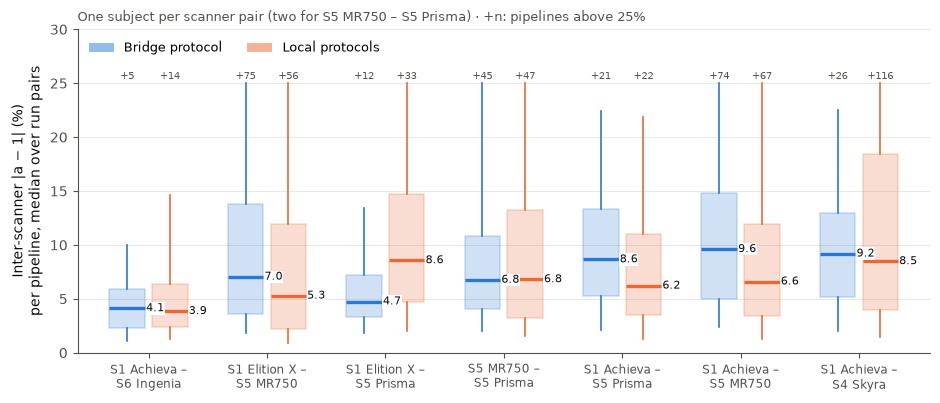

In [8]:
pp = by_pair.unstack('protocol')
order = pp.groupby('scanner_pair').median().mean(axis=1).sort_values().index
NAMES = {'achieva': 'Achieva', 'elition': 'Elition X', 'ingenia': 'Ingenia', 'mr750': 'MR750', 'prisma': 'Prisma', 'skyra': 'Skyra'}
short = lambda s: ' –\n'.join(f"S{x.split('-')[0][4:]} {NAMES[x.split('-')[1]]}" for x in s.split('|'))
fig, ax = plt.subplots(figsize=(11, 4.2), facecolor='white')
for i, pr in enumerate(order):
    d = pp.xs(pr, level='scanner_pair')
    box(ax, i - 0.18, d.bridge, BRIDGE, cap=25); box(ax, i + 0.18, d.local, LOCAL, cap=25)
ax.set_xticks(range(len(order))); ax.set_xticklabels([short(s) for s in order], fontsize=8.5)
ax.set_xlim(-0.6, len(order) - 0.4); ax.set_ylim(0, 30)
style(ax, 'Inter-scanner |a − 1| (%)\nper pipeline, median over run pairs')
ax.set_title('One subject per scanner pair (two for S5 MR750 – S5 Prisma) · +n: pipelines above 25%', fontsize=9.5, loc='left', color=INK2)
legend(ax)
fig.savefig(FIGDIR / 'fig2_scanner_pairs.png', dpi=200, bbox_inches='tight', facecolor='white')

**How to say it.** "The variation between scanner pairs is as large as the deviation itself: an IQR of about 6% against a median of 6–7%. But every pair is a different subject, so this mixes scanner and subject. With these data we cannot say whether it's the scanners or the people."

**Same site vs different sites.** The one same-site pair, S5 MR750 – S5 Prisma (GE vs Siemens, different local protocols), agrees no better than the pairs between sites:

In [9]:
site = lambda s: s.str.split('-').str[0]
rel = np.where(site(isc.scanner_x) == site(isc.scanner_y), 'same site', 'different sites')
(100 * isc.groupby([rel, 'protocol', 'pipeline']).abs_slope_dev.median().groupby(level=[0, 1]).median()).unstack().round(2)

protocol,bridge,local
different sites,6.73,6.64
same site,6.76,6.80


**Is bridge better than local across scanners?** Not at the median: 6.4% vs 7.0%. Before the abstract it was 6.7% vs 6.8%, using matched runs only. Per pipeline it's close to a coin flip. The bootstrap over subjects (resampling the 6 subjects with replacement, 500 times; rough with only four multi-scanner subjects) puts the median difference's 95% interval across zero. The bridge advantage is in the tail: fewer pipelines go badly wrong.

In [10]:
both = per_pipe.dropna()
print(f'share of pipelines where bridge < local: {(both.bridge < both.local).mean():.2f}')
b = FU['bootstrap_over_subjects']
pd.DataFrame({k.replace('inter_scanner_', ''): {'estimate': b[k]['estimate'], 'ci95 low': b[k]['ci95'][0], 'ci95 high': b[k]['ci95'][1]}
              for k in ('inter_scanner_median_bridge_minus_local_pct', 'inter_scanner_p75_bridge_minus_local_pct',
                        'inter_scanner_p95_bridge_minus_local_pct')}).T

share of pipelines where bridge < local: 0.52


,estimate,ci95 low,ci95 high
median_bridge_minus_local_pct,-0.21,-0.46,1.03
p75_bridge_minus_local_pct,-2.55,-3.39,-0.17
p95_bridge_minus_local_pct,-6.20,-35.62,-1.56


## Figure 3 · Limits of agreement before and after removing the scaling

**Question ([#3](https://github.com/astewartau/emtp-travelling-heads/issues/3)).** If the premise is a global scaling error, the LoA should be taken after correcting for it. The uncorrected LoA stays useful as a sanity check, since the scaling assumption may not hold for every protocol and pipeline.

**Calculation.** For each pair, from the fit above over up to 25 regions:
- solid: $\mathrm{LoA} = 1.96\,\mathrm{SD}_i(y_i - x_i)$, as in the abstract;
- dashed: $\mathrm{LoA}_{\text{corr}} = 1.96\,\mathrm{SD}_i\big(y_i - (a x_i + b)\big)$, after rescaling y onto x with that pair's own $a$ and $b$.

Per pipeline: the median over its pairs. The boxes show those medians across the 638 pipelines, in ppb.

**A cleaner way to put the size of the scaling effect.** Variances add, so $1 - (\mathrm{LoA}_{\text{corr}}/\mathrm{LoA})^2$ is roughly the share of the variance of the regional differences explained by the pair's line. That share comes out at about 10–15%.

In [11]:
s3 = FU['issue_3_corrected_loa']
rows = {}
for comp in ('test_retest', 'inter_scanner'):
    for p in ('bridge', 'local'):
        d = 1000 * ok[(ok.comparison == comp) & (ok.protocol == p)].groupby('pipeline')[['ba_loa_ppm', 'ba_loa_corrected_ppm']].median()
        rows[(comp, p)] = {'LoA ±ppb': d.ba_loa_ppm.median(), 'corrected ±ppb': d.ba_loa_corrected_ppm.median(),
                           'narrower by %': 100 * (1 - d.ba_loa_corrected_ppm.median() / d.ba_loa_ppm.median()),
                           'variance explained by the line %': 100 * (1 - (d.ba_loa_corrected_ppm / d.ba_loa_ppm) ** 2).median()}
        check(f'{comp} {p} LoA', d.ba_loa_ppm.median(), s3[f'{comp}_{p}']['loa_ppb']['median'])
        check(f'{comp} {p} corrected LoA', d.ba_loa_corrected_ppm.median(), s3[f'{comp}_{p}']['loa_corrected_ppb']['median'])
pd.DataFrame(rows).T.round(1)

check ok  test_retest bridge LoA: 8.73 (followup.json 8.73)
check ok  test_retest bridge corrected LoA: 8.31 (followup.json 8.31)
check ok  test_retest local LoA: 5.61 (followup.json 5.61)
check ok  test_retest local corrected LoA: 5.32 (followup.json 5.32)
check ok  inter_scanner bridge LoA: 19.05 (followup.json 19.05)
check ok  inter_scanner bridge corrected LoA: 17.97 (followup.json 17.97)


check ok  inter_scanner local LoA: 17.50 (followup.json 17.50)
check ok  inter_scanner local corrected LoA: 16.22 (followup.json 16.22)


LoA ±ppb  corrected ±ppb  narrower by %  \
test_retest   bridge       8.7             8.3            4.8   
              local        5.6             5.3            5.2   
inter_scanner bridge      19.1            18.0            5.7   
              local       17.5            16.2            7.3   

                      variance explained by the line %  
test_retest   bridge                              10.0  
              local                                9.2  
inter_scanner bridge                               9.4  
              local                               14.1

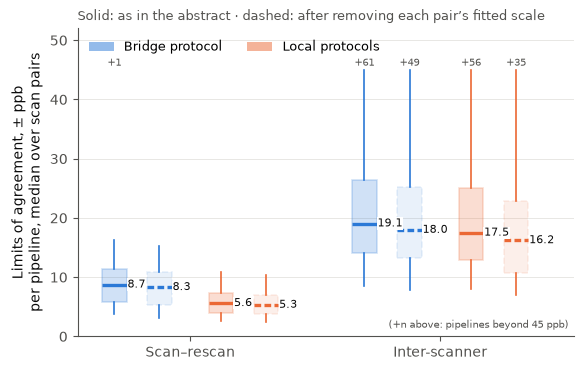

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 4), facecolor='white')
pos, ticks = 0, []
for comp, lab in [('test_retest', 'Scan–rescan'), ('inter_scanner', 'Inter-scanner')]:
    d = ok[ok.comparison == comp]
    for prot, col in (('bridge', BRIDGE), ('local', LOCAL)):
        g = 1000 * d[d.protocol == prot].groupby('pipeline')[['ba_loa_ppm', 'ba_loa_corrected_ppm']].median()
        box(ax, pos, g.ba_loa_ppm, col, cap=45); box(ax, pos + 0.55, g.ba_loa_corrected_ppm, col, light=True, cap=45)
        pos += 1.3
    ticks.append((pos - 1.3 - 0.65 + 0.275, lab)); pos += 0.45
ax.set_xticks([t for t, _ in ticks]); ax.set_xticklabels([l for _, l in ticks])
ax.set_xlim(-0.45, pos - 0.5); ax.set_ylim(0, 52)
ax.text(0.99, 0.02, '(+n above: pipelines beyond 45 ppb)', transform=ax.transAxes, fontsize=7.5, color=INK2, ha='right', va='bottom')
style(ax, 'Limits of agreement, ± ppb\nper pipeline, median over scan pairs')
ax.set_title('Solid: as in the abstract · dashed: after removing each pair’s fitted scale', fontsize=9.5, loc='left', color=INK2)
legend(ax)
fig.savefig(FIGDIR / 'fig3_loa_corrected.png', dpi=200, bbox_inches='tight', facecolor='white')

**How to say it.** "Removing each pair's own scaling only narrows the inter-scanner LoA from ±19 to ±18 ppb (bridge) and ±17.5 to ±16 ppb (local). So most of the disagreement is regions moving independently, not a global scale."

**Why so little, when |a − 1| is 6–7%?** A 6% scale error moves a region at +150 ppb (pallidum) by 9 ppb, but a region near 0 (WM, cortex) hardly at all. Across 25 regions, most of which sit near zero, the scaling adds only a small part of the variance next to the region-by-region scatter.

**Possible questions.**
- *Is the corrected LoA optimistic?* Slightly. The line is fitted to the same ~25 points it corrects (2 parameters out of ~25), so it can only shrink the scatter. That makes "only 5–8%" a generous upper bound on what scale correction buys.
- *Bias?* Values are relative to each map's whole-brain mean, so the bias $\overline{y - x}$ is small. The LoA shown is the half-width $1.96\,\mathrm{SD}$ around the bias.
- *Why ddof = 1?* That is the sample SD. QSM-CI uses ddof = 0, so its LoA are about 2.5% narrower for a 20-region fit (`extraction/README.md`).

## Figure 4 · Sources of variability, with the protocol bar corrected for scaling

**Question ([#4](https://github.com/astewartau/emtp-travelling-heads/issues/4)).** What does "Protocol" in Fig. 4 of the abstract mean, and shouldn't it be corrected for $a$?

**How every bar is defined** (`emtp.spread`). Take the bilateral mean χ of one region (voxel-weighted over the hemispheres present, in ppb). Each bar is the SD when **one factor varies and the others are fixed**. Within a pipeline we take the median over the subjects and scanners it applies to, then the median over pipelines:

| Bar | SD over… | Holding fixed |
|---|---|---|
| Rescan | the 3 runs | pipeline, subject, scanner, protocol |
| Protocol | the 2 run-averaged values (bridge, local) | pipeline, subject, scanner |
| Scanner | the run-averaged values on each scanner the subject was scanned on | pipeline, subject, protocol |
| Pipeline | all 638 run-averaged pipeline values (median over the scan conditions, not over pipelines) | subject, scanner, protocol |
| Between subjects | the 6 subjects on the site-1 Achieva (run-averaged) | pipeline, protocol |

**Protocol in plain words.** For two values the SD is $|\Delta|/\sqrt 2$. So "protocol = 3.0 ppb" in the pallidum means the run-averaged bridge and local means typically differ by about 4.2 ppb.

**Correction (hatched bar).** For each pipeline and scanner, take $a, b$ as the median of that scanner's local-vs-bridge fits (bridge = x) over all its subjects and runs. Map every local value into bridge space with $\chi' = (\chi - b)/a$, then recompute the protocol bar. The transform is estimated **on the same scans it corrects**, so this is a best case. The honest, out-of-sample version is Fig. 6.

In [13]:
ip = ok[ok.comparison == 'inter_protocol']
ab = ip.groupby(['pipeline', 'scanner_x'])[['slope', 'intercept_ppm']].median()
ab.index.names = ['pipeline', 'scanner']
rc = reg.merge(acq[['acquisition', 'scanner', 'protocol']], on='acquisition').join(ab, on=['pipeline', 'scanner'])
m = (rc.protocol == 'local') & rc.slope.notna()
rc.loc[m, 'mean_ppm'] = (rc.mean_ppm[m] - rc.intercept_ppm[m]) / rc.slope[m]
reg_protocol_corrected = rc[reg.columns]
print(f'local-vs-bridge slope per pipeline and scanner: median {ab.slope.median():.3f} (IQR {ab.slope.quantile(.25):.3f}–{ab.slope.quantile(.75):.3f})')

spread_before = {R: emtp.spread(reg, R) for R in ('Caudate', 'Pallidum')}
spread_after = {R: emtp.spread(reg_protocol_corrected, R) for R in ('Caudate', 'Pallidum')}
for R in spread_before:
    print(f'\n{R} (SD, ppb)'); display(spread_before[R].round(1))
    check(f'{R} protocol SD', spread_before[R].loc['protocol', 'both'], FU['issue_4_protocol_spread'][R]['protocol_sd_ppb'])
    check(f'{R} protocol SD after correction', spread_after[R].loc['protocol', 'both'], FU['issue_4_protocol_spread'][R]['protocol_sd_corrected_ppb'])

local-vs-bridge slope per pipeline and scanner: median 0.987 (IQR 0.956–1.022)



Caudate (SD, ppb)


,bridge,local,both
rescan,1.7,1.0,1.3
protocol,NaN,NaN,2.1
scanner,2.6,4.1,3.0
pipeline,21.5,20.8,21.1
between_subjects,13.2,12.9,13.1


check ok  Caudate protocol SD: 2.07 (followup.json 2.10)
check ok  Caudate protocol SD after correction: 1.81 (followup.json 1.80)

Pallidum (SD, ppb)


,bridge,local,both
rescan,2.4,2.0,2.1
protocol,NaN,NaN,3.0
scanner,6.5,6.8,6.9
pipeline,29.2,34.3,31.3
between_subjects,29.3,27.6,28.6


check ok  Pallidum protocol SD: 3.05 (followup.json 3.00)
check ok  Pallidum protocol SD after correction: 2.09 (followup.json 2.10)


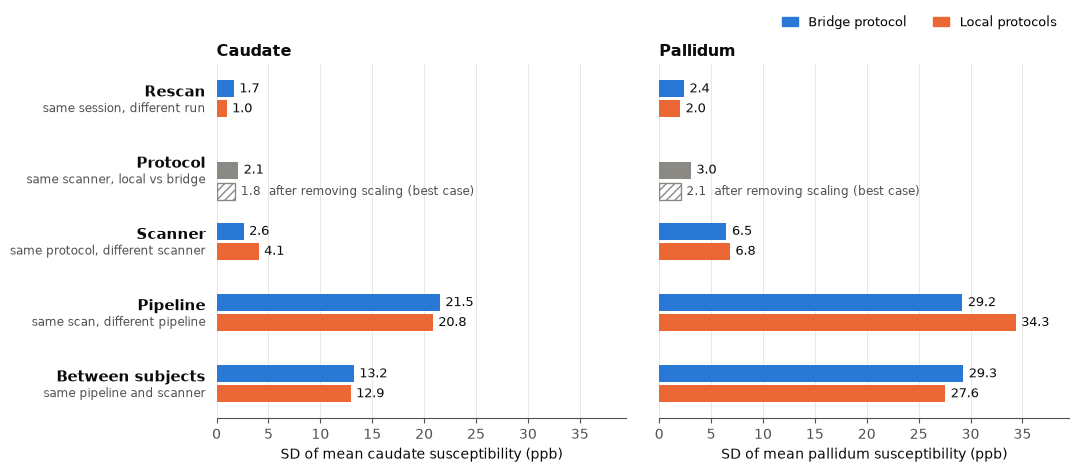

In [14]:
import fig4_sources_of_variability as f4

fig = f4.make(reg)
for ax in fig.axes[:2]:
    R = ax.get_title(loc='left')
    val, y = spread_after[R].loc['protocol', 'both'], 1 + 0.30
    ax.barh(y, val, height=0.24, color='white', edgecolor=f4.PROTOCOL_COL, hatch='////', lw=1)
    ax.annotate(f'{val:.1f}  after removing scaling (best case)', (val, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5, color=INK2)
fig.savefig(FIGDIR / 'fig4_protocol_corrected.png', dpi=200, bbox_inches='tight', facecolor='white')

**How to say it.** "The protocol bar is the bridge–local difference itself, written as an SD. It ignores a. If I first map local into bridge space with each scanner's median local-to-bridge fit, it drops from 2.1 to 1.8 ppb in the caudate and from 3.0 to 2.1 ppb in the pallidum, roughly rescan level. But that transform was fitted on the same scans, so it's the best case."

**Possible questions.**
- *Is the bar inflated by rescan noise?* A little. Each of the two values is a mean of 3 runs, so rescan noise adds about $\mathrm{SD}_{\text{rescan}}/\sqrt 3$ to each one.
- *Why are the bars not corrected in the figure?* Decision D4: the corrected bars are in-sample. They will be corrected once there are enough sessions to estimate the transform out of sample.

## Figure 5 · One conversion factor per pipeline

**Question ([#6](https://github.com/astewartau/emtp-travelling-heads/issues/6)).** Are the differences between pipelines a global factor that could be converted away?

**Calculation.**
1. **Typical pipeline.** For each acquisition and region: the median over all 638 pipelines of that region's mean χ. This is the "consensus" map.
2. For every pipeline and acquisition, fit the pipeline's regional values (y) against the consensus (x) with the same orthogonal fit. That gives $a_{p,s}, b_{p,s}$ for pipeline p and scan s.
3. **Conversion factor of a pipeline** = the median $a, b$ over the **site-1 Achieva bridge scans only** (5 subjects × 3 runs). Apply $\chi' = (\chi - b)/a$ to all of that pipeline's scans.
4. Recompute the Fig. 4 "Pipeline" bar (SD across pipelines, same scan) on the **held-out scans**, i.e. everything except the site-1 Achieva bridge scans. This tests whether a factor learned on one scanner and protocol carries over to the others.

The other bars (rescan, protocol, scanner, between subjects) are the uncorrected Fig. 4 values, there for scale.

In [15]:
vals = followup.region_values(reg)                                   # {pipeline: {acquisition: {label: ppm}}}
cons = reg.groupby(['acquisition', 'label']).mean_ppm.median()       # consensus: median over pipelines
cons = {a: g.droplevel(0).to_dict() for a, g in cons.groupby(level=0)}
rows = []
for pipe, pv in vals.items():
    for a, v_ in pv.items():
        f = followup.fit_dicts(cons[a], v_)                         # emtp.fit with the QSM-CI exclusions
        if f:
            rows.append(dict(pipeline=pipe, acquisition=a, slope=f['slope'], intercept_ppm=f['intercept_ppm']))
pf = pd.DataFrame(rows).merge(acq, on='acquisition')

ref = (pf.scanner == 'site1-achieva') & (pf.protocol == 'bridge')
factor = pf[ref].groupby('pipeline')[['slope', 'intercept_ppm']].median()
conv = reg.join(factor, on='pipeline'); conv = conv[conv.slope.notna()].copy()
conv['mean_ppm'] = (conv.mean_ppm - conv.intercept_ppm) / conv.slope
conv = conv[reg.columns]
held_out = set(acq.acquisition[~((acq.scanner == 'site1-achieva') & (acq.protocol == 'bridge'))])

pc = FU['issue_6_pipeline_conversion']
for R in ('Caudate', 'Pallidum'):
    before = emtp.spread(reg[reg.acquisition.isin(held_out)], R).loc['pipeline']
    after = emtp.spread(conv[conv.acquisition.isin(held_out)], R).loc['pipeline']
    print(f'{R}: pipeline SD on held-out scans  bridge {before.bridge:.1f} -> {after.bridge:.1f} ppb,  local {before.local:.1f} -> {after.local:.1f} ppb')
    for p in ('bridge', 'local'):
        check(f'{R} {p} pipeline SD after one factor', after[p], pc[R]['global_from_reference_bridge']['pipeline_sd_held_out_scans_ppb'][p])

Caudate: pipeline SD on held-out scans  bridge 18.2 -> 9.9 ppb,  local 20.8 -> 12.3 ppb
check ok  Caudate bridge pipeline SD after one factor: 9.92 (followup.json 9.90)
check ok  Caudate local pipeline SD after one factor: 12.33 (followup.json 12.30)


Pallidum: pipeline SD on held-out scans  bridge 29.2 -> 16.7 ppb,  local 34.3 -> 16.3 ppb
check ok  Pallidum bridge pipeline SD after one factor: 16.65 (followup.json 16.70)
check ok  Pallidum local pipeline SD after one factor: 16.28 (followup.json 16.30)


**How stable is a pipeline's factor?** Within each pipeline, take the SD of $\ln a$ (≈ relative SD of $a$) across runs, protocols, scanners and subjects (run-averaged), and set it against how much pipelines differ from each other:

In [16]:
pf['ln_a'] = np.log(pf.slope.clip(lower=1e-3))
run_avg = pf.groupby(['pipeline', 'subject', 'scanner', 'protocol']).ln_a.mean().reset_index()
within = pd.Series({
    'runs': pf.groupby(['pipeline', 'subject', 'scanner', 'protocol']).ln_a.std().groupby('pipeline').median().median(),
    'protocols': run_avg.groupby(['pipeline', 'subject', 'scanner']).ln_a.std().groupby('pipeline').median().median(),
    'scanners': run_avg.groupby(['pipeline', 'subject', 'protocol']).ln_a.std().groupby('pipeline').median().median(),
    'subjects': run_avg[run_avg.scanner == 'site1-achieva'].groupby(['pipeline', 'protocol']).ln_a.std().groupby('pipeline').median().median()})
print('SD of a within a pipeline (%):', (100 * within).round(1).to_dict())
for k in within.index:
    check(f'within-pipeline SD of a across {k}', 100 * within[k], pc['sd_of_slope_within_pipeline_pct'][k]['median'])
pipe_a = pf.groupby('pipeline').slope.median()
print(f'between pipelines: median a vs consensus, IQR {pipe_a.quantile(.25):.2f}–{pipe_a.quantile(.75):.2f}  (about ±15%)')

SD of a within a pipeline (%): {'runs': 1.0, 'protocols': 2.2, 'scanners': 4.3, 'subjects': 5.5}
check ok  within-pipeline SD of a across runs: 0.99 (followup.json 0.99)
check ok  within-pipeline SD of a across protocols: 2.15 (followup.json 2.15)
check ok  within-pipeline SD of a across scanners: 4.29 (followup.json 4.29)
check ok  within-pipeline SD of a across subjects: 5.49 (followup.json 5.49)
between pipelines: median a vs consensus, IQR 0.88–1.20  (about ±15%)


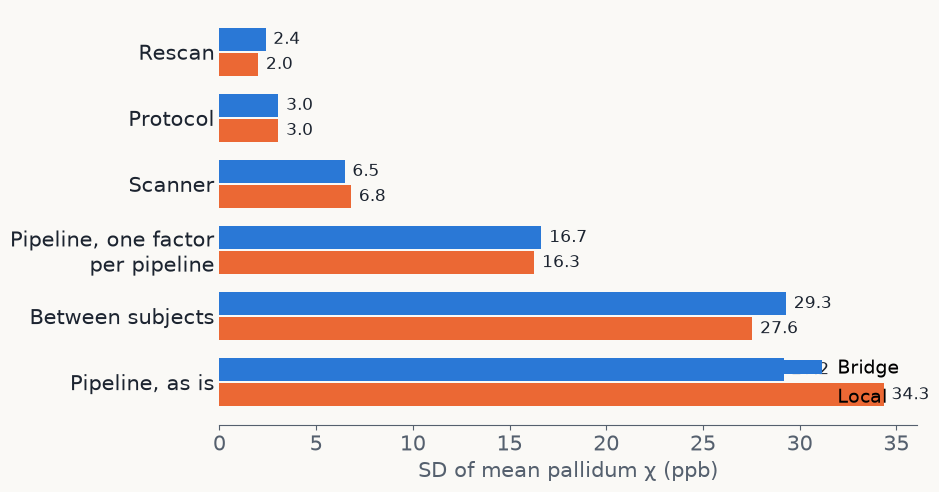

In [17]:
sp = spread_before['Pallidum']
held = emtp.spread(conv[conv.acquisition.isin(held_out)], 'Pallidum').loc['pipeline']
raw_held = emtp.spread(reg[reg.acquisition.isin(held_out)], 'Pallidum').loc['pipeline']
items = [('Rescan', sp.loc['rescan', 'bridge'], sp.loc['rescan', 'local']),
         ('Protocol', sp.loc['protocol', 'both'], sp.loc['protocol', 'both']),
         ('Scanner', sp.loc['scanner', 'bridge'], sp.loc['scanner', 'local']),
         ('Pipeline, one factor\nper pipeline', held.bridge, held.local),
         ('Between subjects', sp.loc['between_subjects', 'bridge'], sp.loc['between_subjects', 'local']),
         ('Pipeline, as is', raw_held.bridge, raw_held.local)]
with plt.rc_context(DECK):
    fig, ax = plt.subplots(figsize=(9, 5.4))
    y = np.arange(len(items)); w = 0.38
    for j, (col, lab) in enumerate([(BRIDGE, 'Bridge'), (LOCAL, 'Local')]):
        xs = [it[1 + j] for it in items]
        ax.barh(y + (j - 0.5) * w, xs, w * 0.9, color=col, label=lab)
        for yi, xi in zip(y + (j - 0.5) * w, xs):
            ax.text(xi + 0.4, yi, f'{xi:.1f}', va='center', fontsize=12.5, color='#1C2430')
    ax.set_yticks(y); ax.set_yticklabels([it[0] for it in items]); ax.invert_yaxis()
    ax.set_xlabel('SD of mean pallidum χ (ppb)'); ax.legend(frameon=False, fontsize=14, loc='lower right')
    ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
    fig.savefig(FIGDIR / 'fig5_pipeline_conversion.png', dpi=200, bbox_inches='tight', pad_inches=0.15)

**How to say it.** "Each pipeline gets one slope and intercept relative to a typical pipeline, learned on the site-1 bridge scans. Applied to all the other scans, it roughly halves the spread between pipelines: 29–34 ppb becomes 16–17 ppb in the pallidum. So the factors carry over: a varies about 2% across protocols, 4% across scanners and 5% across subjects, while pipelines differ by about ±15%. But what's left is still much bigger than the scanner (3–7 ppb) or protocol (2–3 ppb) spread. Using the same pipeline beats converting between pipelines."

**Possible questions.**
- *Why the median over pipelines as the reference?* It's robust to the failed pipelines, and a factor of 1 then means "typical". The choice of reference doesn't change the spread *between* converted pipelines much, because every pipeline gets its own a and b.
- *What is the remaining 16–17 ppb?* The part of each pipeline's deviation that isn't a straight line: region-specific differences such as background-removal erosion at the edges or under-estimated deep grey matter in some inversions. Those vary by region, not by a global scale.
- *Does the conversion hurt the between-subject differences?* No: between subjects goes from 29.3 to 28.4 ppb (bridge), so the biology is kept.

## Figure 6 · Does a local-to-bridge calibration help a new subject?

**Question ([#5](https://github.com/astewartau/emtp-travelling-heads/issues/5)).** The framework idea is to learn, per scanner, how the local protocol maps to the bridge, and then use that to bring local-only data into bridge space.

**Calculation (leave one subject out).** Use the scanners with at least two subjects: site-1 Achieva (5), site-5 MR750 (2) and site-5 Prisma (2).
1. For each pipeline, scanner and subject: the subject's local-to-bridge transform is the median $a, b$ over its 3 inter-protocol fits (bridge run k = x, local run k = y).
2. For each held-out subject: $a, b$ = the median of the **other** subjects' transforms on that scanner. With only 2 subjects, that means the other one.
3. Map the held-out subject's local scan into bridge space, $\chi' = (\chi - b)/a$, refit it against the bridge scan of the same run, and record $|a' - 1|$.
4. Compare three cases. *No correction*: $|a-1|$ as fitted. *Other subjects*: the honest test. *Same subject*: the subject's own transform, the in-sample best case, impossible in practice.

Per pipeline: the median over all held-out subjects, scanners and runs. The boxes show that value across pipelines.

In [18]:
per_subj = ip.groupby(['pipeline', 'scanner_x', 'subject_x'])[['slope', 'intercept_ppm']].median()
n_subj = ip.groupby('scanner_x').subject_x.nunique()
scanners = n_subj[n_subj >= 2].index.tolist()
print('scanners with >= 2 subjects:', n_subj[scanners].to_dict())
rows = []
for r in ip[ip.scanner_x.isin(scanners)].itertuples():
    own = per_subj.loc[(r.pipeline, r.scanner_x)]
    others = own.drop(index=r.subject_x)
    if others.empty:                      # this pipeline has no usable fit for any other subject on this scanner
        continue
    vx, vy = vals[r.pipeline][r.acquisition_x], vals[r.pipeline][r.acquisition_y]
    out = dict(pipeline=r.pipeline, scanner=r.scanner_x, subject=r.subject_x, none=r.abs_slope_dev)
    for lab, (a_, b_) in (('loso', others.median()), ('in_sample', own.loc[r.subject_x])):
        f = followup.fit_dicts(vx, {k: (val - b_) / a_ for k, val in vy.items()})
        out[lab] = abs(f['slope'] - 1) if f else np.nan
    rows.append(out)
cal = pd.DataFrame(rows)
cal_pp = 100 * cal.groupby('pipeline')[['none', 'loso', 'in_sample']].median()
display(cal_pp.median().round(2).to_frame('median over pipelines (%)').T)
c5 = FU['issue_5_calibration']
for k in ('none', 'loso', 'in_sample'):
    check(f'calibration {k}', cal_pp[k].median(), c5['all'][f'{k}_abs_slope_dev']['median'])
sd_a = 100 * per_subj.slope.groupby(['pipeline', 'scanner_x']).std().groupby('scanner_x').median().dropna()
print('SD of the local-to-bridge slope between subjects (%, median over pipelines):', sd_a.round(1).to_dict())

scanners with >= 2 subjects: {'site1-achieva': 5, 'site5-mr750': 2, 'site5-prisma': 2}


,none,loso,in_sample
median over pipelines (%),3.97,4.2,1.01


check ok  calibration none: 3.97 (followup.json 3.97)
check ok  calibration loso: 4.20 (followup.json 4.20)
check ok  calibration in_sample: 1.01 (followup.json 1.01)
SD of the local-to-bridge slope between subjects (%, median over pipelines): {'site1-achieva': 3.7, 'site5-mr750': 2.8, 'site5-prisma': 4.7}


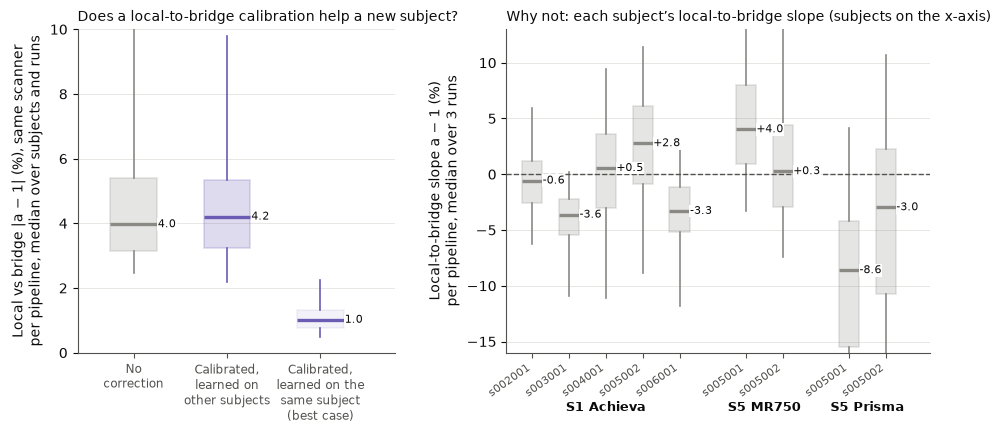

In [19]:
GREY, PURPLE = '#8a8984', '#6b5bb3'
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), facecolor='white', gridspec_kw={'width_ratios': [1.2, 1.6], 'wspace': 0.3})
for i, (k, col, al) in enumerate([('none', GREY, 0.22), ('loso', PURPLE, 0.22), ('in_sample', PURPLE, 0.08)]):
    box(a1, i, cal_pp[k], col, w=0.5, alpha=al)
a1.set_xticks(range(3)); a1.set_xticklabels(['No\ncorrection', 'Calibrated,\nlearned on\nother subjects', 'Calibrated,\nlearned on the\nsame subject\n(best case)'], fontsize=8.8)
a1.set_xlim(-0.6, 2.8); a1.set_ylim(0, 10)
style(a1, 'Local vs bridge |a − 1| (%), same scanner\nper pipeline, median over subjects and runs')
a1.set_title('Does a local-to-bridge calibration help a new subject?', fontsize=10, loc='left', color=INK)

ps = 100 * (ip.groupby(['scanner_x', 'subject_x', 'pipeline']).slope.median() - 1)
SC = {'site1-achieva': 'S1 Achieva', 'site5-mr750': 'S5 MR750', 'site5-prisma': 'S5 Prisma'}
pos, ticks, groups = 0, [], []
for sc in SC:
    start = pos
    for s in sorted(ps.loc[sc].index.get_level_values(0).unique()):
        box(a2, pos, ps.loc[(sc, s)].values, GREY, w=0.55, fmt='{:+.1f}'); ticks.append((pos, s)); pos += 1
    groups.append(((start + pos - 1) / 2, SC[sc])); pos += 0.8
a2.axhline(0, color=INK2, lw=1, ls='--')
a2.set_xticks([t for t, _ in ticks]); a2.set_xticklabels([s for _, s in ticks], fontsize=8, rotation=35, ha='right')
for xg, lab in groups:
    a2.annotate(lab, (xg, 0), xycoords=('data', 'axes fraction'), xytext=(0, -42), textcoords='offset points', ha='center', fontsize=9.5, color=INK, fontweight='bold')
a2.set_xlim(-0.7, pos - 0.6); a2.set_ylim(-16, 13)
style(a2, 'Local-to-bridge slope a − 1 (%)\nper pipeline, median over 3 runs')
a2.set_title('Why not: each subject’s local-to-bridge slope (subjects on the x-axis)', fontsize=10, loc='left', color=INK)
fig.savefig(FIGDIR / 'fig6_calibration.png', dpi=200, bbox_inches='tight', facecolor='white')

**How to say it.** "Learning the local-to-bridge mapping from the other subjects and applying it to a new one gives no gain: 4.0% before, 4.2% after. Using the subject's own mapping gets to 1.0%, but that's circular. The right panel shows why. The slope moves 3–5% from one subject to the next on the same scanner, around a median of 0.99, so there's no stable offset to learn. With protocols this similar there isn't much to calibrate."

**Possible questions.**
- *Isn't this just too few subjects?* Partly. Two of the three scanners have only two subjects, so "the others" is a single person. But the between-subject SD of the slope (3–5%) is as large as the effect itself on the 5-subject scanner too.
- *Why is local vs bridge on the same scanner (4%) bigger than scan-rescan (1.4–2.2%)?* It compares two different acquisitions with different echo times, resolution and readout. Even matched runs (bridge k vs local k) differ by more than rescan noise. It's just not consistent across subjects.
- *S5 Prisma, s005001 at −8.6%?* That subject's local protocol reads lower than its bridge on the Prisma for most pipelines. Another subject on the same scanner doesn't show it (−3.0%), which is the point.

## Figure 7 · Bridge run 1 is the odd one out

**Question ([#10](https://github.com/astewartau/emtp-travelling-heads/issues/10)).** Why does the bridge look noisier in scan-rescan?

**Calculation.** For each session (subject × scanner), protocol and run pair (1–2, 1–3, 2–3): the median $|a-1|$ over pipelines. Each pipeline has exactly one fit per run pair. Dots = the two pairs containing run 1; diamond = run 2 vs run 3.

**The count.** Run 1 is "the odd one out" when **both** pairs containing it are worse than run 2 vs run 3. Equivalently, run 2 vs run 3 is the best-agreeing of the three pairs. Under the null hypothesis that run 1 is nothing special, each of the three pairs is equally likely to be the best one, so the chance is 1/3 per session. Treating the 12 sessions as independent: $P(X \ge 9 \mid n = 12, p = 1/3) \approx 0.004$.

In [20]:
t = (tr.groupby(['subject_x', 'scanner_x', 'protocol', 'run_x', 'run_y', 'pipeline']).abs_slope_dev.median()
     .groupby(['subject_x', 'scanner_x', 'protocol', 'run_x', 'run_y']).median().mul(100).unstack(['run_x', 'run_y']))
t.columns = [f'{a}_vs_{b}' for a, b in t.columns]
t = t.reset_index()
t['run1_odd'] = (t.run1_vs_run2 > t.run2_vs_run3) & (t.run1_vs_run3 > t.run2_vs_run3)
counts = t.groupby('protocol').run1_odd.agg(['sum', 'size'])
counts['expected by chance'] = counts['size'] / 3
counts['p (binomial, one-sided)'] = [binom.sf(k - 1, n, 1 / 3) for k, n in zip(counts['sum'], counts['size'])]
display(counts.round(4))
check('bridge sessions with run 1 odd', counts.loc['bridge', 'sum'], FU['issue_10_first_run']['odd_run_per_session']['bridge']['run1'], tol=0)
t[t.protocol == 'bridge'].round(2)

,sum,size,expected by chance,"p (binomial, one-sided)"
protocol,,,,
bridge,9,12,4.0,3.90e-03
local,4,12,4.0,6.07e-01


check ok  bridge sessions with run 1 odd: 9.00 (followup.json 9.00)


,subject_x,scanner_x,protocol,run1_vs_run2,run1_vs_run3,run2_vs_run3,run1_odd
0,s002001,site1-achieva,bridge,3.60,3.02,1.15,True
2,s003001,site1-achieva,bridge,1.77,1.39,1.43,False
4,s004001,site1-achieva,bridge,3.10,2.99,1.25,True
6,s004001,site4-skyra,bridge,2.62,4.61,2.15,True
8,s005001,site1-elition,bridge,5.49,6.57,1.60,True
10,s005001,site5-mr750,bridge,1.85,1.46,1.43,True
12,s005001,site5-prisma,bridge,2.48,3.56,1.28,True
14,s005002,site1-achieva,bridge,1.74,3.80,5.05,False
16,s005002,site5-mr750,bridge,2.14,2.83,4.73,False
18,s005002,site5-prisma,bridge,2.44,1.55,1.42,True


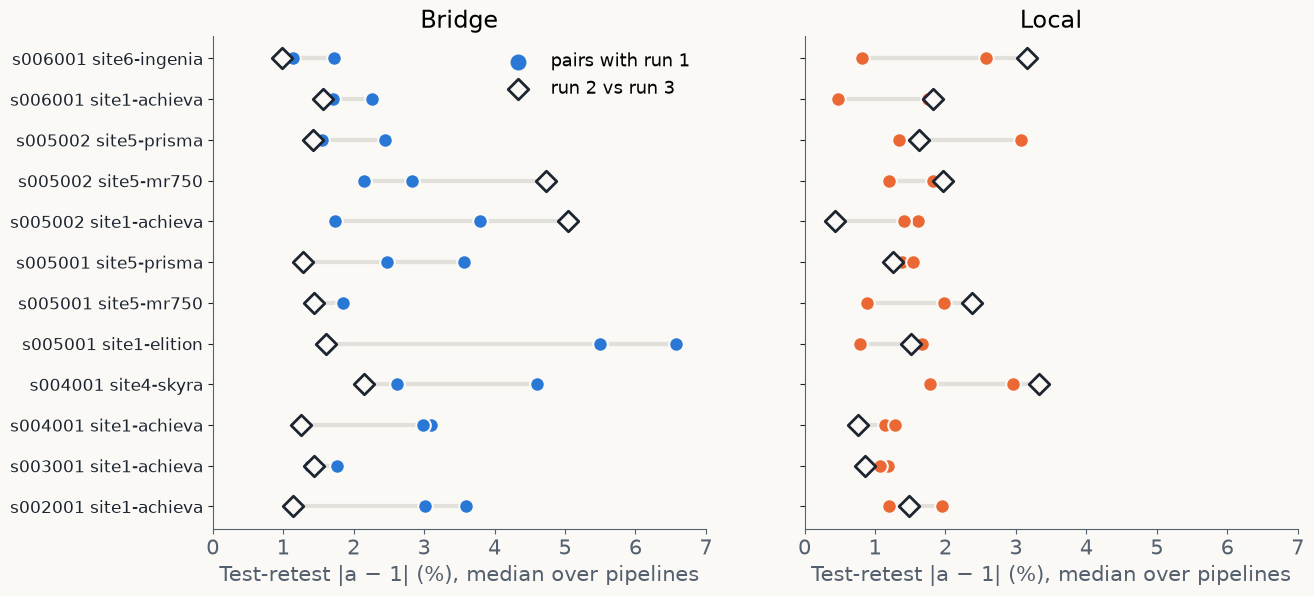

In [21]:
t['session'] = t.subject_x + ' ' + t.scanner_x
with plt.rc_context(DECK):
    fig, axs = plt.subplots(1, 2, figsize=(14, 6.4), sharey=True)
    for ax, prot, c in zip(axs, ('bridge', 'local'), (BRIDGE, LOCAL)):
        g = t[t.protocol == prot].sort_values('session').reset_index(drop=True)
        for i, r in g.iterrows():
            ax.plot([r.run1_vs_run2, r.run1_vs_run3, r.run2_vs_run3], [i] * 3, color='#E2E0DA', lw=3, zorder=1)
            ax.scatter([r.run1_vs_run2, r.run1_vs_run3], [i, i], s=110, color=c, edgecolors='#FAF9F6', linewidths=1.5, zorder=3)
            ax.scatter([r.run2_vs_run3], [i], s=110, marker='D', facecolor='#FAF9F6', edgecolors='#1C2430', linewidths=2, zorder=4)
        ax.set_yticks(range(len(g))); ax.set_yticklabels(g.session, fontsize=12); ax.invert_yaxis()
        ax.set_title(prot.capitalize(), fontsize=17); ax.set_xlabel('Test-retest |a − 1| (%), median over pipelines'); ax.set_xlim(0, 7)
    axs[0].scatter([], [], s=110, color=BRIDGE, label='pairs with run 1')
    axs[0].scatter([], [], s=110, marker='D', facecolor='#FAF9F6', edgecolors='#1C2430', linewidths=2, label='run 2 vs run 3')
    axs[0].legend(frameon=False, fontsize=13, loc='upper right')
    fig.savefig(FIGDIR / 'fig7_run_pairs_sessions.png', dpi=200, bbox_inches='tight', pad_inches=0.15)

**How to say it.** "Nearly all the extra bridge deviation comes from one scan per session: bridge run 1, the first QSM scan, which usually came after a structural. In 9 of 12 sessions, run 2 vs run 3 is the best-agreeing bridge pair. By chance you'd expect 4 (p ≈ 0.004). The local protocol, acquired in between, doesn't show it (4 of 12)."

**Possible questions.**
- *Some of the 9 are marginal.* Yes. s005001 on the MR750 is 1.46 / 1.85 vs 1.43. The clear cases are s002001, s004001 on both scanners, s005001 on the Elition and on the Prisma. s005002 on the Achieva and on the MR750 go the other way: there run 3 is the odd one.
- *Are the sessions independent?* The p-value assumes so. Several sessions share a subject (s005001 has three). It is a descriptive test, not a formal one.
- *What have we ruled out?* Head motion within the session (≈ 0.5° between runs, no larger for run 1), ghosting and edge sharpness (`data/image_quality.csv`), and field drift between runs (a few Hz, the same for both protocols, `data/b0_drift.csv`). Still open: head-support pillows settling over the first 3–5 minutes, scanner warm-up (at site 1, s002001 was the first scan of the day, and s004001 and s005001 came after a gap of more than 30 minutes), and physiological settling. Randomising or counterbalancing the run order, or adding a dummy scan first, would test this (decision D6).
- *Bridge run 1 always comes first, so is this the first scan or the bridge protocol?* The design can't separate them. That is why counterbalancing is proposed.

## Figure 8 · Results with and without run 1

**Calculation.** As in Figs. 1–2: per pipeline, the median $|a-1|$ over its pairs; the boxes show that across pipelines. "Without run 1" drops every pair in which either scan is run 1:
- test-retest keeps 1 of 3 pairs per session (run 2 vs run 3), so 12 per pipeline;
- inter-scanner keeps 4 of 9 run combinations (runs 2–3 × runs 2–3), so 32 per pipeline.

Because test-retest keeps only 12 pairs, its "without run 1" boxes are wider. The median is taken over fewer values.

check ok  test_retest bridge without run 1: 1.64 (followup.json 1.64)
check ok  test_retest local without run 1: 1.50 (followup.json 1.50)
check ok  inter_scanner bridge without run 1: 6.40 (followup.json 6.40)


check ok  inter_scanner local without run 1: 6.81 (followup.json 6.81)


all pairs  without run 1
test_retest   bridge       2.21           1.64
              local        1.42           1.50
inter_scanner bridge       6.36           6.40
              local        6.98           6.81

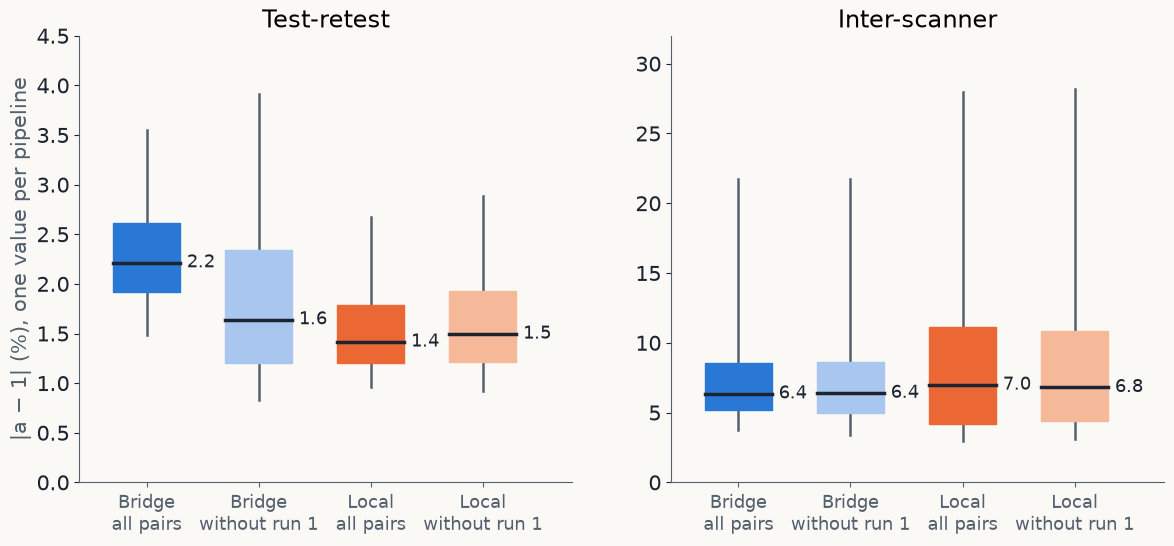

In [22]:
def per_pipeline(comp, prot, drop_run1=False):
    d = ok[(ok.comparison == comp) & (ok.protocol == prot)]
    if drop_run1:
        d = d[~d.with_run1]
    return 100 * d.groupby('pipeline').abs_slope_dev.median()


fr = FU['issue_10_first_run']
tab = {}
for comp in ('test_retest', 'inter_scanner'):
    for p in ('bridge', 'local'):
        allp, wo = per_pipeline(comp, p), per_pipeline(comp, p, True)
        tab[(comp, p)] = {'all pairs': allp.median(), 'without run 1': wo.median()}
        check(f'{comp} {p} without run 1', wo.median(), fr[comp][p]['pairs_without_run1_pct']['median'])
display(pd.DataFrame(tab).T.round(2))


def deck_boxes(ax, data, labels, colors):
    for i, (d, c) in enumerate(zip(data, colors)):
        q = np.percentile(d, [5, 25, 50, 75, 95])
        ax.plot([i, i], [q[0], q[1]], color='#55606E', lw=1.8); ax.plot([i, i], [q[3], q[4]], color='#55606E', lw=1.8)
        ax.add_patch(plt.Rectangle((i - 0.3, q[1]), 0.6, q[3] - q[1], color=c, zorder=2))
        ax.plot([i - 0.3, i + 0.3], [q[2], q[2]], color='#1C2430', lw=2.5, zorder=3)
        ax.text(i + 0.36, q[2], f'{q[2]:.1f}', va='center', fontsize=13, color='#1C2430')
    ax.set_xticks(range(len(data))); ax.set_xticklabels(labels, fontsize=13); ax.set_xlim(-0.6, len(data) - 0.2)


labels = ['Bridge\nall pairs', 'Bridge\nwithout run 1', 'Local\nall pairs', 'Local\nwithout run 1']
colors = [BRIDGE, '#A9C7EE', LOCAL, '#F5B99A']
with plt.rc_context(DECK):
    fig, axs = plt.subplots(1, 2, figsize=(14, 5.8))
    for ax, comp, title, ylim in ((axs[0], 'test_retest', 'Test-retest', 4.5), (axs[1], 'inter_scanner', 'Inter-scanner', 32)):
        deck_boxes(ax, [per_pipeline(comp, p, w) for p in ('bridge', 'local') for w in (False, True)], labels, colors)
        ax.set_title(title, fontsize=17); ax.set_ylim(0, ylim)
    axs[0].set_ylabel('|a − 1| (%), one value per pipeline')
    fig.savefig(FIGDIR / 'fig8_without_run1.png', dpi=200, bbox_inches='tight', pad_inches=0.15)

**How to say it.** "Leave run 1 out and bridge and local scan-rescan are the same, 1.6% vs 1.5%. The inter-scanner results barely move: bridge 6.4% either way, local 7.0% vs 6.8%. So the bridge may not be noisier as a protocol, and its length may matter less than we thought. The comparison across scanners doesn't depend on run 1."

**Why doesn't inter-scanner change?** Inter-scanner differences (6–7%) are much bigger than the extra run-1 noise (~1%). Noise adds in quadrature: $\sqrt{6.4^2 + 1^2} \approx 6.5$, so removing it barely shows.

## Caveats that apply to everything

- **The sample size is people, not pipelines.** 638 pipelines × many pairs looks like a lot of data, but it all comes from 6 subjects and 12 sessions, and from only 4 subjects for inter-scanner. Pipelines, run pairs and run combinations share scans, so they aren't independent. The only formal tests here are the bootstrap over subjects (Fig. 2) and the binomial count over sessions (Fig. 7).
- **Scanner and subject are confounded.** Most scanner pairs have one subject, and site 1's two scanners never share a subject.
- **Head position between sessions.** The head's angle to B0 changes by 2.5–15° between sessions but only ~0.5° within one. Every between-session pair is also a different scanner, and the largest angles are all in the GE sessions. With 8 session pairs, head position and scanner can't be told apart (`data/head_pose.csv`).
- **All 638 pipelines are included everywhere**, including poor ones. Medians and percentiles keep them from dominating, and the tails (p75, p95, +n) show them.
- **Regions are per hemisphere and include cortex, WM and cerebellum.** The slope is driven mostly by the deep grey matter, which has the largest χ range.
- **Data version.** QSMxT v10.0.0. The v11 re-run, with QSM.rs ports corrected to match their references, and the five October sessions (sites 2 and 3, including a single-echo 0.8 mm local protocol) will change these numbers.